# Process the goggles-monocular session

Builds the `MonocularDevice` (eye-conditioned), runs `SessionAnalyzer.analyze_session_stats`,
and saves `{session_name}_dataframe.pkl` next to the session data. That pkl is what
`monocular-disparity-distance-comparison.ipynb` reads for this experiment via
`CrossExperimentAnalysis.from_devices(R, M, D)`.

Run this in its own kernel with **only** `disparity-analysis` on `sys.path`.

In [54]:
import sys, os
import pandas as pd

base_dir = r"C:\Users\acostamendoza\projects\distance-project"
for p in (base_dir, base_dir + r"\disparity-analysis"):
    if p not in sys.path:
        sys.path.append(p)

from src.data.MonocularDevice import MonocularDevice
from src.analysis.CellAnalysis import SessionAnalyzer

%load_ext autoreload
%autoreload 2
%matplotlib widget

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [55]:
mouse, date, experiment = "SAM045", "260903", "monocular"
M = MonocularDevice(mouse_name=mouse, record_date=date, experiment_name=experiment)
print("session:", M.session_name, "| eyes:", M.present_eyes, "| cells:", len(M.suite2p_id))

Creating directory: results
session: 260903_SAM045_monocular | eyes: ['right', 'left'] | cells: 258


In [56]:
# load cached stats if present, else compute once (slow) and save the pkl the
# comparison notebook reads
pkl_path = os.path.join(M.data_dir, f"{M.session_name}_dataframe.pkl")
if os.path.exists(pkl_path):
    stats_df = pd.read_pickle(pkl_path)
    print(f"Loaded cached stats: {pkl_path}")
else:
    stats_df = SessionAnalyzer(M).analyze_session_stats(n_iterations=200)
    SessionAnalyzer(M).save_dataframe(stats_df)   # -> pkl_path
stats_df.head()

Saved DataFrame to: D:/data-distance-coding-project/processed-data\260903_SAM045_monocular\260903_SAM045_monocular_dataframe.pkl


,cell,session_name,right_reliable,right_mean_corr,right_rf,right_rf_value,right_px,left_reliable,left_mean_corr,left_rf,left_rf_value,left_px,ODI
0,0,260903_SAM045_monocular,True,0.878451,0,0.232727,37.200000,False,0.163789,10,0.528460,52.071186,-0.388516
1,1,260903_SAM045_monocular,False,0.618615,51,0.408844,76.616949,False,-0.089884,13,0.370394,49.752542,0.049343
2,2,260903_SAM045_monocular,True,0.739961,0,0.301643,37.200000,False,-0.103937,29,0.453153,37.386441,-0.200730
3,3,260903_SAM045_monocular,True,0.650829,9,0.452776,44.155932,False,-0.172759,48,0.390194,22.701695,0.074239
4,4,260903_SAM045_monocular,False,0.592944,3,0.304320,39.518644,False,-0.219370,59,0.295675,14.200000,0.014408


In [51]:
# --- save the standard report for this session ---
from src.viz.SessionVisualizer import SessionVisualizer

sv = SessionVisualizer(M, stats_df=stats_df, corr_threshold=0.7)

# summary/ (summary + plots + map) and one folder per group of reliable cells
# plot_cells=False -> summary folder only, skips the slow per-cell figures
sets = sv.save_report(plot_cells=True)

reliable_cells = sorted(sets["either"])    # reliable in left OR right eye
print(f"{len(reliable_cells)} cells reliable in at least one eye")

 Session: 260902_SAM045_monocular
 Eyes shown: right, left
 Total cells: 987
 mean_corr floor: 0.7
--------------------------------------------------
 Right reliable        :    0  (  0.0%)
 Left reliable         :   42  (  4.3%)
 Both eyes reliable    :    0  (  0.0%)
--------------------------------------------------
 Right-only            :    0
 Left-only             :   42
 Either eye            :   42  (  4.3%)
 Neither               :  945  ( 95.7%)
42 cells reliable in at least one eye


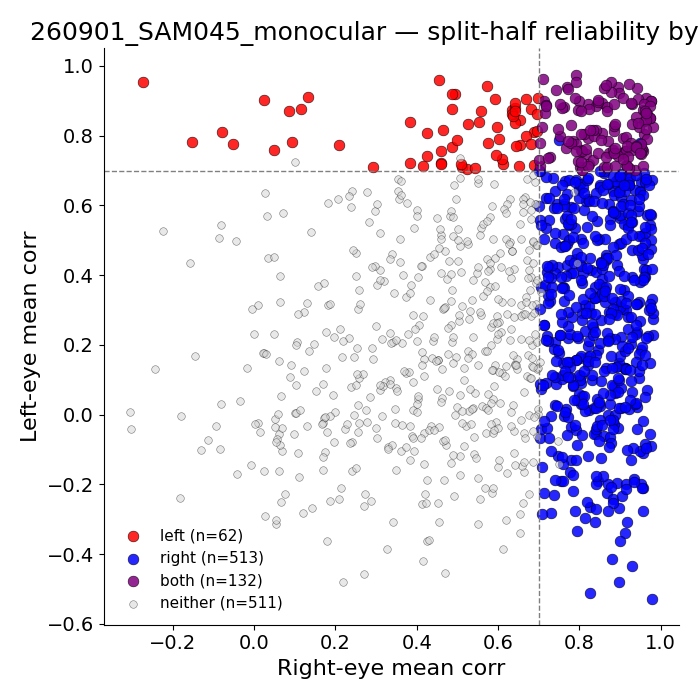

In [45]:
fig = sv.plot_corr_scatter()

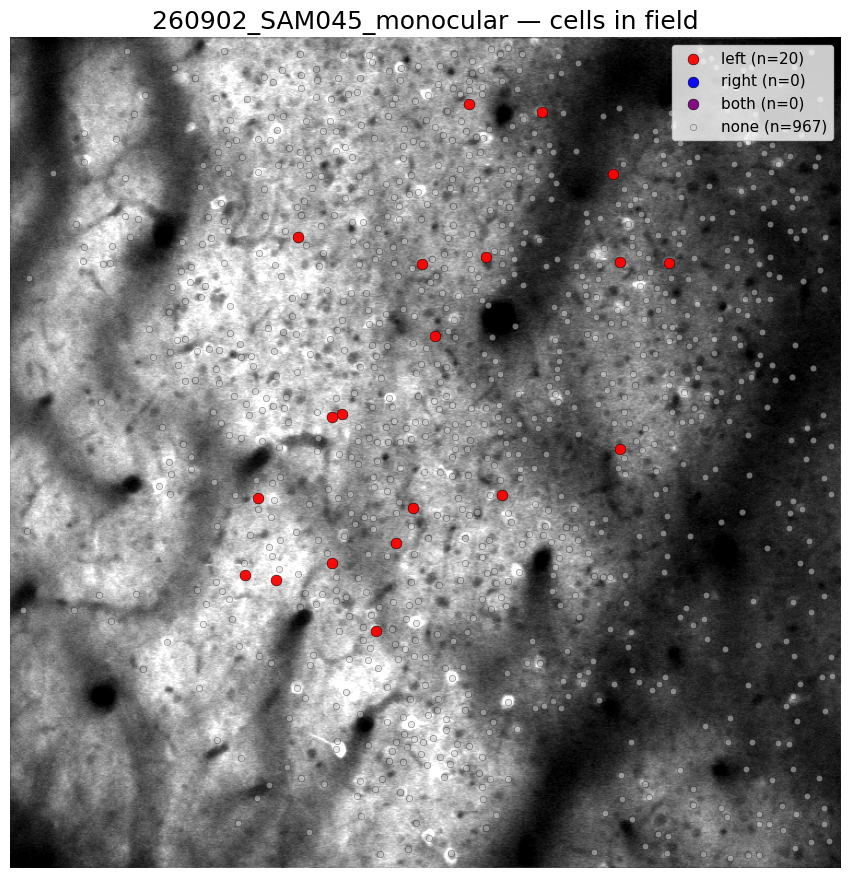

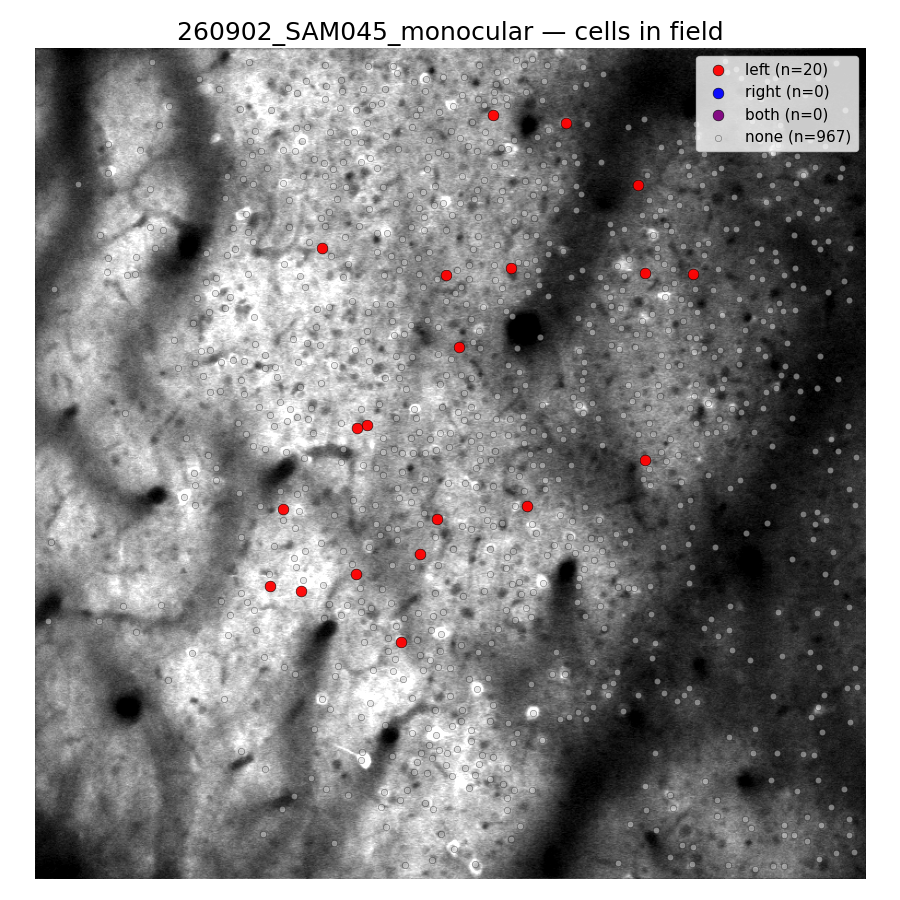

In [53]:
sv.plot_location_map(corr_threshold=0.75)

C:\Users\acostamendoza\projects\distance-project\disparity-analysis\src\viz\SessionVisualizer.py:448: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


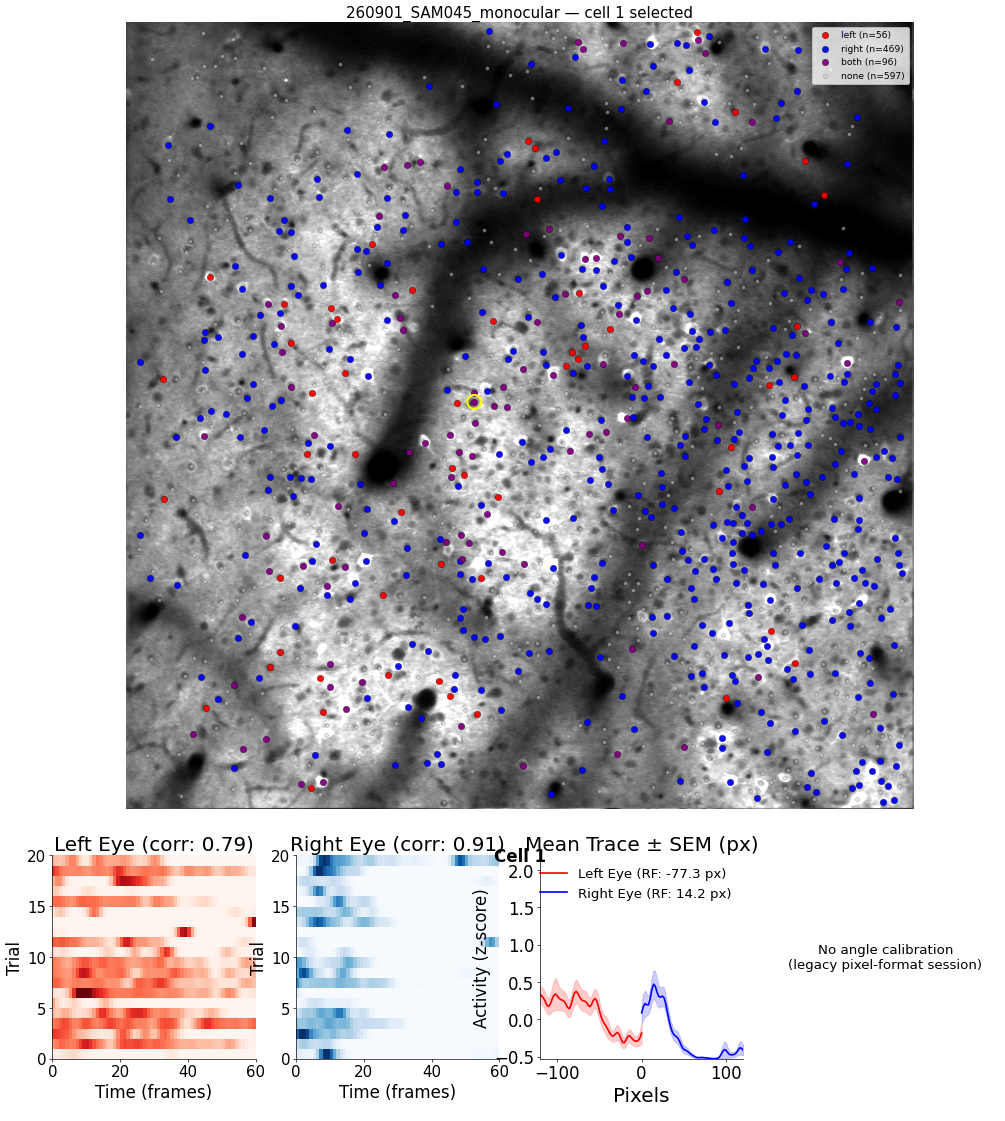

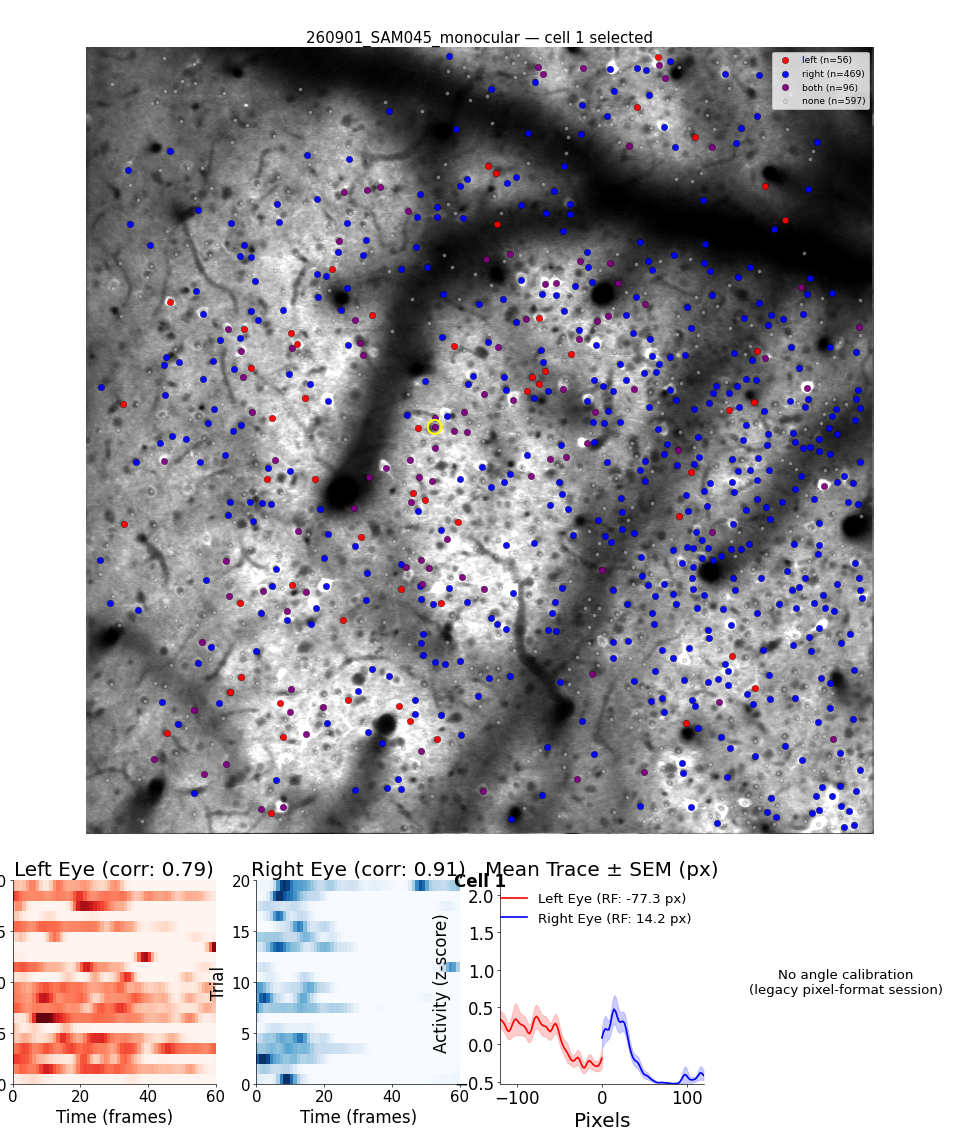

In [47]:
from src.viz.SessionVisualizer import SessionVisualizer
from src.viz.CellVisualizer import CellVisualizer
from src.viz.InteractiveCellExplorer import InteractiveCellExplorer

sv = SessionVisualizer(M, stats_df=stats_df, corr_threshold=0.75)
cv = CellVisualizer(M, stats_df=stats_df)

explorer = InteractiveCellExplorer(sv, cv)
explorer.show()   # top: location map; bottom: make_comparison_plot for a starting cell